# PRAKTIKUM PERTEMUAN 11 — GAUSSIAN NAIVE BAYES DAN SVM
## 150 menit | Pembuktian manual → implementasi scikit-learn → data Iris nyata → evaluasi adil

**Mata kuliah:** DAIS32W — Pembelajaran Mesin · Semester 3  
**Nama:** Samuel Mare Papiang **NIM:** 235314076 **Kelas:** EP

**Kompetensi setelah praktikum:**
1. Memverifikasi **prior, mean, varians, likelihood Gaussian, posterior** untuk dua batch Iris, lalu memeriksa hasil dengan `GaussianNB`.
2. Menghubungkan **margin dan hinge loss** SVM dengan **update SGD satu dan dua fitur**, serta membuktikan prediksi manual.
3. Melatih `GaussianNB` dan `SVC` pada **Iris asli**, memakai training / validation / test terpisah tanpa leakage.
4. Menjelaskan fungsi parameter `priors`, `var_smoothing`, `kernel`, `C`, `gamma`, `degree`, dan `coef0` **berdasarkan eksperimen**.
5. Membandingkan kedua algoritma menggunakan **Macro-F1, confusion matrix, serta kesalahan per kelas**, bukan intuisi saja.

  
**Perangkat:** Python 3, Jupyter Notebook/JupyterLab/Google Colab, `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `IPython`. Dataset `load_iris()` sudah tersedia dalam scikit-learn.  
**Instruksi:. Isi jawaban **di notebook ini**, simpan output perhitungan dan gambar, serta **jangan memakai hasil test untuk memilih model**.

> **Dua eksperimen berbeda.** (A) Demonstrasi manual hanya memakai beberapa ID Iris dan bukan skor generalisasi. (B) Percobaan algoritma memakai split formal 90/30/30. Delapan ID demonstrasi diletakkan di **training** sejak awal agar tidak mencemari validation/test. Total Iris tetap 150 observasi.

## P11.1 — Setup dan pembagian data tanpa leakage

**Konsep penting:** `load_iris(as_frame=True)` mengambil 150 observasi dengan empat pengukuran numerik. `train_test_split` mempunyai parameter:

| Parameter | Fungsi |
|---|---|
| `train_size` / `test_size` | Menentukan jumlah atau proporsi baris yang dipisahkan |
| `random_state` | Menetapkan urutan acak agar eksperimen dapat direproduksi |
| `stratify` | Menjaga komposisi kelas pada pemisahan sedekat mungkin |

ID demonstrasi manual telah ditetapkan berdasarkan modul: `50,51,52,53,100,101,102,123`. **Tidak satu pun masuk validation/test**. Sisa data dibagi stratified menjadi 82 train tambahan, 30 validation, dan 30 test. Dengan delapan ID latihan, train berjumlah 90. Test tetap disimpan tetapi baru dievaluasi pada P11.8.

In [13]:
import sys, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, recall_score, confusion_matrix,
                             classification_report)

SEED=2026
np.set_printoptions(suppress=True, precision=6)
plt.rcParams.update({'figure.figsize':(6.8,4.0),'font.size':10})
print('Python:',sys.version.split()[0],'| scikit-learn:',sklearn.__version__)
iris=load_iris(as_frame=True)
raw=iris.data.rename(columns={
 'sepal length (cm)':'sepal_length','sepal width (cm)':'sepal_width',
 'petal length (cm)':'petal_length','petal width (cm)':'petal_width'}).copy()
raw['kelas_id']=np.asarray(iris.target,dtype=int)
raw['kelas']=[str(iris.target_names[int(i)]) for i in iris.target]
raw.index.name='iris_id'
PETAL=['petal_length','petal_width']
DEMO_IDS=[50,51,52,53,100,101,102,123]
remaining_ids=raw.index[~raw.index.isin(DEMO_IDS)]
extra_train_ids,hold_ids=train_test_split(
 remaining_ids,train_size=82,test_size=60,random_state=SEED,
 stratify=raw.loc[remaining_ids,'kelas_id'])
val_ids,test_ids=train_test_split(hold_ids,train_size=30,test_size=30,
 random_state=SEED+1,stratify=raw.loc[hold_ids,'kelas_id'])
train_ids=np.concatenate([np.array(DEMO_IDS),np.array(extra_train_ids)])
X_all=raw[['sepal_length','sepal_width']+PETAL]
y_all=raw['kelas_id']
X_train=X_all.loc[train_ids].copy(); y_train=y_all.loc[train_ids].copy()
X_val=X_all.loc[val_ids].copy(); y_val=y_all.loc[val_ids].copy()
X_test=X_all.loc[test_ids].copy(); y_test=y_all.loc[test_ids].copy()  # disimpan hingga P11.8
X_tr=X_train[PETAL].copy(); X_va=X_val[PETAL].copy()
assert (len(X_train),len(X_val),len(X_test))==(90,30,30)
assert len(set(train_ids)&set(val_ids))==len(set(train_ids)&set(test_ids))==0
assert set(DEMO_IDS).issubset(set(train_ids))
print('Data keseluruhan:',raw.shape, '| split:',len(train_ids),len(val_ids),len(test_ids))
print('Target:',dict(enumerate(iris.target_names)))
display(raw.head(4))
print('Kelas TRAIN:',y_train.value_counts().sort_index().to_dict())

Python: 3.13.18 | scikit-learn: 1.6.1
Data keseluruhan: (150, 6) | split: 90 30 30
Target: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


,sepal_length,sepal_width,petal_length,petal_width,kelas_id,kelas
iris_id,,,,,,
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa


Kelas TRAIN: {0: 29, 1: 31, 2: 30}


**PERTANYAAN P11.1-1** — Jelaskan mengapa data Iris merupakan supervised classification dan mengapa 8 ID demonstrasi dimasukkan ke training, bukan ke validation/test.

**✍ JAWABAN MAHASISWA P11.1-1**

1. Iris sebagai supervised classification

Dataset Iris terdiri dari 150 observasi. Setiap observasi memiliki vektor fitur x = (sepal_length, sepal_width, petal_length, petal_width) berupa empat pengukuran numerik dalam cm, dan label kelas y ∈ {0 = setosa, 1 = versicolor, 2 = virginica} yang sudah diketahui. Tujuan pembelajaran adalah memperoleh fungsi pemetaan f: x → y dari pasangan (x, y) pada data training, lalu menggunakannya untuk memprediksi kelas bunga yang belum pernah dilihat model.

Tugas ini termasuk supervised learning karena label tersedia selama pelatihan dan berfungsi sebagai pengawas (supervisor) bagi proses estimasi parameter. Variabel targetnya diskret dan terdiri dari tiga kategori, sehingga masalahnya adalah klasifikasi multikelas, bukan regresi (target kontinu) dan bukan clustering (tanpa label).

2. Alasan delapan ID demonstrasi dimasukkan ke training

Delapan ID demonstrasi (50, 51, 52, 53, 100, 101, 102, 123) dipakai pada eksperimen A untuk menghitung prior, mean, varians, likelihood Gaussian, posterior, margin, hinge loss, dan update SGD secara manual. Data ini sudah terlibat dalam penurunan parameter, sehingga statusnya sama dengan data training.

Jika ID tersebut berada di validation atau test, informasinya ikut membentuk parameter model sebelum model dievaluasi pada data yang sama. Akibatnya skor evaluasi menjadi terlalu optimis dan tidak lagi mengukur kemampuan generalisasi. Kondisi ini disebut data leakage. Prinsip yang dipegang:

training: satu-satunya bagian yang boleh digunakan untuk belajar,
validation: hanya untuk memilih hyperparameter (var_smoothing, C, gamma, dan seterusnya),
test: hanya untuk evaluasi akhir pada P11.8, tanpa dipakai memilih model.

Dengan menempatkan delapan ID demo di training sejak awal, eksperimen A (demonstrasi, bukan skor generalisasi) tidak mencemari eksperimen B (evaluasi formal 90/30/30).

3. Substitusi angka

Delapan ID demo ditetapkan lebih dulu ke training, sehingga sisa data yang dibagi secara acak adalah

150 − 8 = 142 observasi.

Pembagian bertahap dengan stratify:

142 → 82 (tambahan training) + 60 (hold-out),
60 → 30 (validation) + 30 (test).

Ukuran training akhir = 8 + 82 = 90, sehingga 90 + 30 + 30 = 150. Pernyataan assert pada kode membuktikan irisan antara train, validation, dan test adalah himpunan kosong (0 ID yang beririsan), dan ukuran masing-masing split sesuai (90, 30, 30).

Komposisi kelas pada training adalah setosa 29, versicolor 31, dan virginica 30 (total 90). ID 50-53 adalah versicolor dan ID 100, 101, 102, 123 adalah virginica, sehingga masing-masing kelas tersebut menyumbang 4 ID demo, sedangkan setosa tidak menyumbang. Karena itu, komposisi training sedikit lebih banyak pada versicolor dan virginica dibandingkan setosa. Ini bukan masalah karena stratify hanya diterapkan pada 142 data sisa, dan proporsi kelas pada validation dan test tetap seimbang (masing-masing 10 per kelas). Parameter random_state (SEED = 2026 untuk pemisahan pertama dan SEED + 1 untuk pemisahan kedua) membuat pembagian dapat direproduksi.

## P11.2 — Verifikasi GaussianNB manual, dua batch

Sesuai Bab 3 Modul 11, kita mempelajari **Versicolor (V)** dan **Virginica (G)** menggunakan **dua fitur asli** tanpa shifting:

- **Batch 1:** Iris 50 dan 51 (V), 100 dan 101 (G) → **4 baris**.
- **Batch 2:** Iris 52 (V), 102 (G) → **2 baris baru**, sehingga kumulatif **6 baris**.
- **Titik yang diprediksi:** Iris **ID 53** = (4,0; 1,3), dan **ID 123** = (4,9; 1,8). Nilai kelas aslinya tidak dipakai menghitung prediksi.

Untuk setiap kelas k dan fitur j, hitung:

$$P(C_k)=n_k/N, \quad \mu_{jk}=\frac{1}{n_k}\sum_{i:y_i=k}x_{ij}, \quad
\sigma^2_{jk}=\frac{1}{n_k}\sum_{i:y_i=k}(x_{ij}-\mu_{jk})^2.$$

**Perhatian:** penyebut varians adalah **n**, bukan n−1 (`ddof=0`). Contoh manual menggunakan **smoothing aditif** $\sigma^2_{efektif}=\sigma^2+\delta$, dengan $\delta=0{,}05$; ini **bukan nilai parameter** `var_smoothing=0.05` di scikit-learn.

Bukti Gaussian untuk sebuah fitur:

$$p(x_j\mid C_k)=\frac{1}{\sqrt{2\pi\sigma^2_{efektif,jk}}}
\exp\!\left[-\frac{(x_j-\mu_{jk})^2}{2\sigma^2_{efektif,jk}}\right].$$

Skor kelas $S_k=P(C_k)\prod_j p(x_j\mid C_k)$. Posterior $P(C_k\mid x)=S_k/\sum_r S_r$. Gaussian menghasilkan **densitas**, yang boleh melebihi 1; jangan menyamakan densitas dengan probabilitas kelas.

In [14]:
NB_BATCH1=[50,51,100,101]
NB_BATCH2=[52,102]
NB_SIX=NB_BATCH1+NB_BATCH2
NB_QUERY=[53,123]
DELTA=.05
print('Data latihan GaussianNB manual:')
display(raw.loc[NB_SIX,PETAL+['kelas']])
print('Data uji manual (fitur saja; kelas disembunyikan):')
display(raw.loc[NB_QUERY,PETAL])

def manual_stats(ids):
    frame=raw.loc[ids,PETAL+['kelas']]
    rows=[]; params={}
    for klass in ['versicolor','virginica']:
        dat=frame.loc[frame['kelas']==klass,PETAL].to_numpy(dtype=float)
        cnt=len(dat); prior=cnt/len(frame)
        mean=dat.mean(axis=0); var=dat.var(axis=0,ddof=0)
        params[klass]={'n':cnt,'prior':prior,'mean':mean,'var':var}
        rows.append({'kelas':klass,'n':cnt,'prior':prior,
          'mean_length':mean[0],'mean_width':mean[1],
          'var_length':var[0],'var_width':var[1]})
    return pd.DataFrame(rows).set_index('kelas'),params

tab_nb1,params_nb1=manual_stats(NB_BATCH1)
tab_nb2,params_nb2=manual_stats(NB_SIX)
print('Batch 1 (N=4):');display(tab_nb1.round(6))
print('Batch 2 kumulatif (N=6):');display(tab_nb2.round(6))
assert np.allclose(params_nb1['versicolor']['mean'],[4.6,1.45])
assert np.allclose(params_nb1['versicolor']['var'],[.01,.0025])
assert np.allclose(params_nb2['virginica']['mean'],[5.6666666666667,2.1666666666667])

Data latihan GaussianNB manual:


,petal_length,petal_width,kelas
iris_id,,,
50,4.7,1.4,versicolor
51,4.5,1.5,versicolor
100,6.0,2.5,virginica
101,5.1,1.9,virginica
52,4.9,1.5,versicolor
102,5.9,2.1,virginica


Data uji manual (fitur saja; kelas disembunyikan):


,petal_length,petal_width
iris_id,,
53,4.0,1.3
123,4.9,1.8


Batch 1 (N=4):


,n,prior,mean_length,mean_width,var_length,var_width
kelas,,,,,,
versicolor,2,0.5,4.60,1.45,0.0100,0.0025
virginica,2,0.5,5.55,2.20,0.2025,0.0900


Batch 2 kumulatif (N=6):


,n,prior,mean_length,mean_width,var_length,var_width
kelas,,,,,,
versicolor,3,0.5,4.700000,1.466667,0.026667,0.002222
virginica,3,0.5,5.666667,2.166667,0.162222,0.062222


**PERTANYAAN P11.2-1** — Hitung sendiri prior, mean, dan varians populasi untuk **kedua kelas** setelah Batch 1 dan Batch 2. Mengapa prior tetap 0,5 walaupun jumlah observasi berubah?

**✍ JAWABAN MAHASISWA P11.2-1**

Data yang dipakai (petal_length, petal_width):

Versicolor (V): ID 50 = (4,7; 1,4), ID 51 = (4,5; 1,5), ID 52 = (4,9; 1,5)
Virginica (G): ID 100 = (6,0; 2,5), ID 101 = (5,1; 1,9), ID 102 = (5,9; 2,1)

Rumus yang digunakan: P(Cₖ) = nₖ/N, μⱼₖ = (1/nₖ)Σxᵢⱼ, dan σ²ⱼₖ = (1/nₖ)Σ(xᵢⱼ − μⱼₖ)² dengan penyebut n (ddof = 0).

Batch 1 (N = 4; n_V = 2, n_G = 2)

Prior

P(V) = 2/4 = 0,5
P(G) = 2/4 = 0,5

Versicolor (ID 50, 51)

μ_length = (4,7 + 4,5)/2 = 9,2/2 = 4,60
μ_width = (1,4 + 1,5)/2 = 2,9/2 = 1,45
σ²_length = [(4,7 − 4,6)² + (4,5 − 4,6)²]/2 = (0,01 + 0,01)/2 = 0,0100
σ²_width = [(1,4 − 1,45)² + (1,5 − 1,45)²]/2 = (0,0025 + 0,0025)/2 = 0,0025

Virginica (ID 100, 101)

μ_length = (6,0 + 5,1)/2 = 11,1/2 = 5,55
μ_width = (2,5 + 1,9)/2 = 4,4/2 = 2,20
σ²_length = [(6,0 − 5,55)² + (5,1 − 5,55)²]/2 = (0,2025 + 0,2025)/2 = 0,2025
σ²_width = [(2,5 − 2,2)² + (1,9 − 2,2)²]/2 = (0,09 + 0,09)/2 = 0,0900
Batch 2 kumulatif (N = 6; n_V = 3, n_G = 3)

Prior

P(V) = 3/6 = 0,5
P(G) = 3/6 = 0,5

Versicolor (ID 50, 51, 52)

μ_length = (4,7 + 4,5 + 4,9)/3 = 14,1/3 = 4,70
μ_width = (1,4 + 1,5 + 1,5)/3 = 4,4/3 = 1,466667
σ²_length = [(0,0)² + (−0,2)² + (0,2)²]/3 = (0 + 0,04 + 0,04)/3 = 0,08/3 = 0,026667
σ²_width: selisih terhadap 1,466667 adalah −0,066667, 0,033333, 0,033333, sehingga σ² = (0,004444 + 0,001111 + 0,001111)/3 = 0,006667/3 = 0,002222

Virginica (ID 100, 101, 102)

μ_length = (6,0 + 5,1 + 5,9)/3 = 17,0/3 = 5,666667
μ_width = (2,5 + 1,9 + 2,1)/3 = 6,5/3 = 2,166667
σ²_length: selisih 0,333333, −0,566667, 0,233333, sehingga σ² = (0,111111 + 0,321111 + 0,054444)/3 = 0,486667/3 = 0,162222
σ²_width: selisih 0,333333, −0,266667, −0,066667, sehingga σ² = (0,111111 + 0,071111 + 0,004444)/3 = 0,186667/3 = 0,062222

Seluruh hasil hitungan manual sama dengan tabel keluaran manual_stats, dan sesuai dengan tiga assert pada kode.

Mengapa prior tetap 0,5?

Prior dihitung sebagai proporsi kelas, P(Cₖ) = nₖ/N, bukan sebagai jumlah mentah. Pada Batch 2, ditambahkan satu observasi versicolor (ID 52) dan satu observasi virginica (ID 102). Kedua kelas bertambah dengan jumlah yang sama, sehingga

Batch 1: 2/4 = 0,5
Batch 2: (2 + 1)/(4 + 2) = 3/6 = 0,5

Jumlah n dan N berubah, tetapi perbandingan antar kelasnya tidak. Jika batch tambahan tidak seimbang (misalnya hanya menambah versicolor), prior akan bergeser, misalnya menjadi 3/5 = 0,6 untuk V dan 2/5 = 0,4 untuk G.

### Langkah perhitungan posterior dengan kode Python dasar

Kode di bawah **tidak memakai GaussianNB scikit-learn**. Kode hanya menghitung rumus manual menggunakan `numpy` agar setiap langkah dapat diperiksa. `log(score)` dipakai untuk stabilitas; hasilnya sama dengan normalisasi perkalian densitas selama tidak terjadi masalah pembulatan numerik.

Rincian Batch 2 / ID 53 / δ=0,05:


,kelas,prior,likelihood_length,likelihood_width,skor_tanpa_normalisasi,posterior
0,versicolor,0.5,0.058986,1.338069,0.039464,0.999339
1,virginica,0.5,0.001245,0.041926,0.000026,0.000661


Perbandingan posterior manual:


,training,iris_id,delta,P_V,P_G,prediksi
0,Batch 1,53,0.050,0.99648,0.00352,versicolor
1,Batch 1,53,0.005,0.29637,0.70363,virginica
2,Batch 1,123,0.050,0.66826,0.33174,versicolor
3,Batch 1,123,0.005,0.00120,0.99880,virginica
4,Batch 2 kumulatif,53,0.050,0.99934,0.00066,versicolor
5,Batch 2 kumulatif,53,0.005,0.99793,0.00207,versicolor
6,Batch 2 kumulatif,123,0.050,0.82501,0.17499,versicolor
7,Batch 2 kumulatif,123,0.005,0.02611,0.97389,virginica


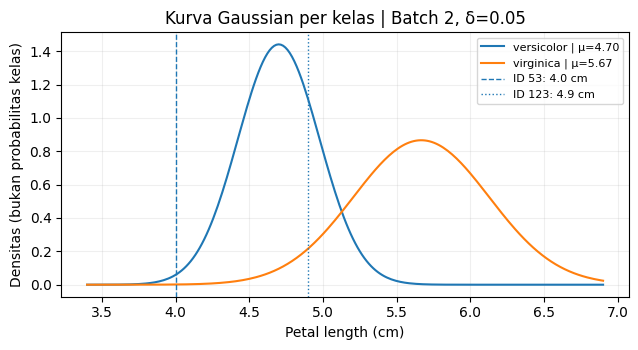

In [15]:
def gaussian_density(x_value,mean,var_eff):
    return 1/np.sqrt(2*np.pi*var_eff)*np.exp(-(x_value-mean)**2/(2*var_eff))

def gaussian_manual_predict(query,parameters,delta):
    rows=[];score=[]
    for klass,p in parameters.items():
        variance_eff=p['var']+delta
        densities=gaussian_density(np.asarray(query),p['mean'],variance_eff)
        unnormalized=p['prior']*np.prod(densities)
        rows.append({'kelas':klass,'prior':p['prior'],
           'likelihood_length':densities[0],'likelihood_width':densities[1],
           'skor_tanpa_normalisasi':unnormalized})
        score.append(unnormalized)
    prob=np.array(score)/np.sum(score)
    result=pd.DataFrame(rows)
    result['posterior']=prob
    return result

posterior_rows=[]
for ids_name,parameters in [('Batch 1',params_nb1),('Batch 2 kumulatif',params_nb2)]:
    for qid in NB_QUERY:
        vals=raw.loc[qid,PETAL].to_numpy(dtype=float)
        for delta in [.05,.005]:
            t=gaussian_manual_predict(vals,parameters,delta)
            pred=t.loc[t['posterior'].idxmax(),'kelas']
            pV=t.loc[t['kelas']=='versicolor','posterior'].iloc[0]
            pG=t.loc[t['kelas']=='virginica','posterior'].iloc[0]
            posterior_rows.append({'training':ids_name,'iris_id':qid,'delta':delta,
                'P_V':pV,'P_G':pG,'prediksi':pred})
            if ids_name=='Batch 2 kumulatif' and qid==53 and delta==.05:
                print('Rincian Batch 2 / ID 53 / δ=0,05:')
                display(t.round(7))
posterior_manual=pd.DataFrame(posterior_rows)
print('Perbandingan posterior manual:')
display(posterior_manual.round(5))
# Visualisasi likelihood Gaussian per kelas untuk satu fitur; gunakan statistik Batch 2.
fig,ax=plt.subplots(figsize=(6.5,3.6))
x_plot=np.linspace(3.4,6.9,230)
for k in ['versicolor','virginica']:
    r=params_nb2[k]
    ax.plot(x_plot,gaussian_density(x_plot,r['mean'][0],r['var'][0]+DELTA),label=f'{k} | μ={r["mean"][0]:.2f}')
ax.axvline(4.0,linestyle='--',linewidth=1,label='ID 53: 4.0 cm')
ax.axvline(4.9,linestyle=':',linewidth=1,label='ID 123: 4.9 cm')
ax.set(xlabel='Petal length (cm)',ylabel='Densitas (bukan probabilitas kelas)',
       title='Kurva Gaussian per kelas | Batch 2, δ=0.05')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()
assert posterior_manual.query("training=='Batch 2 kumulatif' and iris_id==53 and delta==0.05").iloc[0].prediksi=='versicolor'
assert posterior_manual.query("training=='Batch 2 kumulatif' and iris_id==123 and delta==0.005").iloc[0].prediksi=='virginica'

**PERTANYAAN P11.2-2** — Dengan statistik **Batch 2** dan δ=0,05, tulis satu substitusi rumus likelihood untuk ID 53, hitung posterior V dan G, kemudian tentukan prediksi. Apa arti nilai posterior yang sangat tinggi dari enam sampel?

**✍ JAWABAN MAHASISWA P11.2-2**

Titik uji adalah ID 53 dengan x = (4,0; 1,3). Dengan statistik Batch 2 dan δ = 0,05, varians efektif versicolor adalah 0,026667 + 0,05 = 0,076667 (length) dan 0,002222 + 0,05 = 0,052222 (width). Untuk virginica, nilainya 0,162222 + 0,05 = 0,212222 (length) dan 0,062222 + 0,05 = 0,112222 (width).

Substitusi likelihood (versicolor, petal_length):

p(4,0 | V) = 1/√(2π · 0,076667) · exp[−(4,0 − 4,7)² / (2 · 0,076667)]
= 1,440819 · exp(−3,195652)
= 1,440819 · 0,040938
≈ 0,058986

Dengan cara yang sama diperoleh p(width | V) = 1,338069, p(length | G) = 0,001245, dan p(width | G) = 0,041926.

Skor dan posterior:

S_V = 0,5 · 0,058986 · 1,338069 = 0,039464
S_G = 0,5 · 0,001245 · 0,041926 = 0,000026

P(V | x) = 0,039464 / (0,039464 + 0,000026) = 0,99934
P(G | x) = 0,000026 / 0,039490 = 0,00066

Karena P(V | x) > P(G | x), prediksinya versicolor, dan sesuai label asli ID 53. Faktor penentunya adalah jarak ke mean: petal_length 4,0 hanya 0,7 cm dari μ_V = 4,70, tetapi 1,67 cm dari μ_G = 5,67, sedangkan petal_width 1,3 juga jauh lebih dekat ke μ_V (1,47) daripada μ_G (2,17).

Arti posterior yang sangat tinggi dari enam sampel. Nilai 0,99934 hanya berarti bahwa, di bawah asumsi Gaussian dan independensi antarfitur, titik ini jauh lebih sesuai dengan versicolor daripada virginica. Nilai itu bukan peluang nyata bahwa prediksi benar, karena (1) setiap kelas hanya punya tiga titik sehingga estimasi μ dan σ² tidak stabil; (2) asumsi naive mengalikan likelihood length dan width yang sebenarnya berkorelasi, sehingga bukti terhitung ganda dan posterior cenderung terlalu ekstrem; dan (3) hasilnya sensitif terhadap δ dan batch. Pada Batch 1, prediksi ID 53 berbalik dari versicolor (P_V = 0,99648) menjadi virginica (P_G = 0,70363) ketika δ diturunkan dari 0,05 ke 0,005. Karena itu, posterior ini bukan ukuran generalisasi. Ukuran generalisasi baru diperoleh dari evaluasi pada split 90/30/30 di eksperimen B.

**PERTANYAAN P11.2-3** — Pada ID 123, bagaimana kelas prediksi berubah ketika δ diturunkan dari 0,05 menjadi 0,005? Mengapa satu sampel tidak boleh dijadikan dasar penentuan `var_smoothing` terbaik?

**✍ JAWABAN MAHASISWA P11.2-3**

Titik uji ID 123 dengan x = (4,9; 1,8), memakai statistik Batch 2.

Perubahan prediksi. Pada δ = 0,05, varians efektif width versicolor adalah 0,002222 + 0,05 = 0,052222. Densitas width versicolor:

p(1,8 | V) = 1/√(2π · 0,052222) · exp[−(1,8 − 1,466667)² / (2 · 0,052222)] ≈ 0,6025

Posteriornya P(V | x) = 0,82501 dan P(G | x) = 0,17499, sehingga prediksinya versicolor (salah, label asli virginica).

Pada δ = 0,005, varians efektif width versicolor mengecil menjadi 0,007222, sehingga:

p(1,8 | V) = 1/√(2π · 0,007222) · exp[−(0,333333)² / (2 · 0,007222)] ≈ 0,00214

Densitas ini turun sekitar 280 kali, sehingga P(V | x) = 0,02611 dan P(G | x) = 0,97389. Prediksi berubah menjadi virginica (benar). Penyebabnya, jarak 0,333 cm dari μ_V sekitar 1,5 simpangan baku pada δ = 0,05, tetapi sekitar 3,9 simpangan baku pada δ = 0,005.

Mengapa satu sampel tidak boleh dijadikan dasar. Satu sampel hanya memberi hasil benar atau salah, sehingga kebetulan sangat berpengaruh. Pada Batch 1, ID 53 justru benar dengan δ = 0,05 dan salah dengan δ = 0,005, berlawanan dengan ID 123. Selain itu, statistik berasal dari hanya enam titik, dan ID 123 sendiri adalah data demonstrasi di training, bukan data yang tidak terlihat. Karena itu var_smoothing harus dipilih dari beberapa kandidat berdasarkan Macro-F1 pada 30 sampel validation, bukan dari satu titik. Nilai δ manual ini juga bukan var_smoothing scikit-learn, yang dikalikan dengan varians terbesar antar fitur.

## P11.3 — GaussianNB scikit-learn: bukti manual dan training asli

### Panduan fungsi parameter `sklearn.naive_bayes.GaussianNB`

| Parameter/metode | Fungsi | Hal yang perlu dibuktikan |
|---|---|---|
| `priors=None` | Prior dihitung dari proporsi kelas training | `class_prior_` sama dengan n kelas / N |
| `priors=[...]` | Prior ditetapkan pengguna dan **tidak dipelajari dari frekuensi data** | Hanya jika ada alasan ilmiah; jumlah harus 1 dan mengikuti urutan `classes_` |
| `var_smoothing=1e-9` | **Fraksi varians fitur terbesar** yang menjadi tambahan stabilisasi | $\epsilon=\text{var\_smoothing}\cdot\max_j Var(X_j)$, bukan $\epsilon=\text{var\_smoothing}$ |
| `.fit(X,y)` | Mengestimasi prior, mean, dan varians dari semua baris training | Tidak melakukan SGD |
| `.partial_fit(X_batch,y_batch,classes=...)` | Memperbarui statistik saat batch baru masuk | `classes` wajib diberikan pada pemanggilan pertama |
| `.predict(X)` | Memilih kelas posterior terbesar | Menghasilkan **label kelas** |
| `.predict_proba(X)` | Memberikan posterior untuk semua kelas | Kolom sesuai `classes_` dan jumlah baris = 1 |
| `.predict_log_proba(X)` | Log posterior, lebih aman untuk angka kecil | Bukan skor SVM |
| `theta_`, `var_` | Mean dan varians efektif per kelas-fitur setelah fit | Periksa nilai numeriknya |
| `class_prior_`, `class_count_`, `epsilon_` | Prior, jumlah per kelas, tambahan varians absolut | Menjelaskan perubahan hasil contoh manual |

**Uji kesetaraan dengan perhitungan manual:** untuk menambah varians absolut $\delta=0{,}05$ pada contoh enam bunga, **hitung dulu** nilai `var_smoothing=δ/max(var fitur pada keenam bunga)`; jangan langsung `GaussianNB(var_smoothing=0.05)`. Untuk pemeriksaan `partial_fit`, gunakan smoothing nol pada data contoh yang varians per kelasnya tidak nol; ini memungkinkan pemeriksaan statistik mentah tanpa perbedaan aturan smoothing antar batch.

Dokumentasi: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html

In [16]:
X_nb=raw.loc[NB_SIX,PETAL].to_numpy(float)
y_nb=raw.loc[NB_SIX,'kelas'].to_numpy()
X_b1=raw.loc[NB_BATCH1,PETAL].to_numpy(float)
y_b1=raw.loc[NB_BATCH1,'kelas'].to_numpy()
X_b2=raw.loc[NB_BATCH2,PETAL].to_numpy(float)
y_b2=raw.loc[NB_BATCH2,'kelas'].to_numpy()
X_q=raw.loc[NB_QUERY,PETAL].to_numpy(float)

# (A) partial_fit: periksa mean dan varians mentah kumulatif tanpa smoothing
nb_stream=GaussianNB(var_smoothing=0.0)
nb_stream.partial_fit(X_b1,y_b1,classes=np.array(['versicolor','virginica']))
print('partial_fit sesudah Batch 1, mean:');display(pd.DataFrame(nb_stream.theta_,index=nb_stream.classes_,columns=PETAL))
nb_stream.partial_fit(X_b2,y_b2)
print('partial_fit sesudah Batch 2, varians RAW:');display(pd.DataFrame(nb_stream.var_,index=nb_stream.classes_,columns=PETAL))
assert np.allclose(nb_stream.theta_[0],params_nb2['versicolor']['mean'])
assert np.allclose(nb_stream.var_[1],params_nb2['virginica']['var'])

# (B) fit penuh: buat epsilon absolut persis δ=0.05 untuk 6 baris
var_terbesar=float(np.var(X_nb,axis=0,ddof=0).max())
rasio_smoothing=DELTA/var_terbesar
nb_toy=GaussianNB(priors=None,var_smoothing=rasio_smoothing).fit(X_nb,y_nb)
print('Varians seluruh fitur terbesar:',round(var_terbesar,8),
      '| var_smoothing rasio:',round(rasio_smoothing,8),
      '| epsilon_ nyata:',round(nb_toy.epsilon_,8))
assert np.isclose(nb_toy.epsilon_,DELTA)
assert np.allclose(nb_toy.theta_[0],params_nb2['versicolor']['mean'])
assert np.allclose(nb_toy.var_[0],params_nb2['versicolor']['var']+DELTA)
proba_sklearn=nb_toy.predict_proba(X_q)
proba_manual=np.array([gaussian_manual_predict(row,params_nb2,DELTA)['posterior'] for row in X_q])
assert np.allclose(proba_sklearn,proba_manual,atol=1e-10)
print('Perbandingan posterior manual vs sklearn (δ absolut =0,05):')
display(pd.DataFrame({'ID':NB_QUERY,'P_V_manual':proba_manual[:,0],
   'P_V_sklearn':proba_sklearn[:,0],
   'prediksi_sklearn':nb_toy.predict(X_q)}).round(6))

partial_fit sesudah Batch 1, mean:


,petal_length,petal_width
versicolor,4.60,1.45
virginica,5.55,2.20


partial_fit sesudah Batch 2, varians RAW:


,petal_length,petal_width
versicolor,0.026667,0.002222
virginica,0.162222,0.062222


Varians seluruh fitur terbesar: 0.32805556 | var_smoothing rasio: 0.15241321 | epsilon_ nyata: 0.05
Perbandingan posterior manual vs sklearn (δ absolut =0,05):


,ID,P_V_manual,P_V_sklearn,prediksi_sklearn
0,53,0.999339,0.999339,versicolor
1,123,0.825014,0.825014,versicolor


**PERTANYAAN P11.3-1** — Mengapa `GaussianNB(var_smoothing=0.05)` **tidak sama** dengan menambahkan δ=0,05 pada contoh manual? Tunjukkan `epsilon_` dan jelaskan kapan `partial_fit` berguna.

**✍ JAWABAN MAHASISWA P11.3-1**

Pada scikit-learn, var_smoothing adalah fraksi, bukan tambahan absolut. Tambahan varians yang dipakai adalah

ε = var_smoothing · max_j Var(X_j).

Pada enam bunga, varians terbesar adalah petal_length, yaitu 0,32805556. Maka GaussianNB(var_smoothing=0.05) memberi ε = 0,05 · 0,32805556 = 0,016403, bukan 0,05. Varians efektifnya lebih kecil daripada contoh manual, sehingga posteriornya berbeda.

Agar ε = δ = 0,05, nilainya harus dihitung terbalik:

var_smoothing = 0,05 / 0,32805556 = 0,152413.

Dengan nilai ini kode menampilkan epsilon_ = 0,05, dan var_ = varians mentah + ε (versicolor length: 0,026667 + 0,05 = 0,076667). Posterior sklearn untuk ID 53 (0,999339) dan ID 123 (0,825014) sama dengan hitungan manual.

partial_fit berguna ketika data datang bertahap atau terlalu besar untuk dimuat sekaligus, karena prior, mean, dan varians diperbarui kumulatif tanpa melatih ulang. Pada kode, varians mentah setelah Batch 2 (0,026667; 0,002222 untuk versicolor) sama dengan hitungan enam baris. Pada pemanggilan pertama classes wajib diberikan karena model belum melihat semua kelas. Smoothing diset 0 pada pemeriksaan ini karena ε dihitung dari batch yang sedang diproses, sehingga statistik mentah baru bisa dibandingkan langsung tanpa pengaruh ε yang berubah antarbatch.

### Training GaussianNB pada data Iris nyata (90 baris training, 3 kelas)

Di sini bukan lagi enam sampel manual. Kita memakai `X_tr` dan `y_train`, lalu memprediksi `X_va` dari validation. Skor *Macro-F1* dihitung rata-rata F1 per kelas, sehingga ketiga kelas diperhatikan setara. `predict_proba` bisa digunakan karena GaussianNB menghitung posterior, namun probabilitas ini belum tentu terkalibrasi baik.

In [17]:
nb_baseline=GaussianNB(priors=None,var_smoothing=1e-9)
nb_baseline.fit(X_tr,y_train)
nb_val_pred=nb_baseline.predict(X_va)
nb_val_prob=nb_baseline.predict_proba(X_va)
print('Parameter model:',nb_baseline.get_params())
print('Urutan kelas:',nb_baseline.classes_)
print('Prior tiap kelas:',nb_baseline.class_prior_)
print('Mean per kelas dan fitur:')
display(pd.DataFrame(nb_baseline.theta_,index=iris.target_names,columns=PETAL).round(4))
print('Macro-F1 validation GaussianNB:',round(f1_score(y_val,nb_val_pred,average='macro'),4))
print('Confusion matrix validation GaussianNB:')
display(pd.DataFrame(confusion_matrix(y_val,nb_val_pred,labels=[0,1,2]),
    index=['akt_Setosa','akt_Versicolor','akt_Virginica'],
    columns=['pred_Setosa','pred_Versicolor','pred_Virginica']))
print('Lima baris probabilitas posterior (jumlah tiap baris =1):')
display(pd.DataFrame(nb_val_prob[:5],columns=iris.target_names).round(4))
assert np.allclose(nb_val_prob.sum(axis=1),1.0)

Parameter model: {'priors': None, 'var_smoothing': 1e-09}
Urutan kelas: [0 1 2]
Prior tiap kelas: [0.322222 0.344444 0.333333]
Mean per kelas dan fitur:


,petal_length,petal_width
setosa,1.4483,0.2586
versicolor,4.1548,1.2742
virginica,5.5133,2.0500


Macro-F1 validation GaussianNB: 1.0
Confusion matrix validation GaussianNB:


,pred_Setosa,pred_Versicolor,pred_Virginica
akt_Setosa,11,0,0
akt_Versicolor,0,9,0
akt_Virginica,0,0,10


Lima baris probabilitas posterior (jumlah tiap baris =1):


,setosa,versicolor,virginica
0,0.0,1.0000,0.0000
1,0.0,0.9996,0.0004
2,0.0,0.9030,0.0970
3,0.0,0.0005,0.9995
4,1.0,0.0000,0.0000


**PERTANYAAN P11.3-2** — Jelaskan perbedaan keluaran `.predict()` dengan `.predict_proba()`. Apakah prior yang diperoleh dari data training sama untuk tiga kelas? Apa risiko asumsi independensi fitur pada GaussianNB?

**✍ JAWABAN MAHASISWA P11.3-2**
.predict() mengeluarkan satu label kelas per sampel, yaitu kelas dengan posterior terbesar, ŷ = argmax_k P(C_k | x). .predict_proba() mengeluarkan posterior seluruh kelas dalam urutan classes_ = [0, 1, 2], dan setiap baris berjumlah 1 (lolos assert). Pada baris ke-2 posteriornya (0; 0,9030; 0,0970), sehingga predict memberi kelas 1 (versicolor). Pada baris ke-3 posteriornya (0; 0,0005; 0,9995), sehingga predict memberi kelas 2 (virginica).

Prior tidak sama untuk ketiga kelas, karena priors=None membuat prior dihitung dari proporsi training, P(C_k) = n_k/N. Dengan N = 90: setosa 29/90 = 0,322222, versicolor 31/90 = 0,344444, virginica 30/90 = 0,333333, sesuai class_prior_. Perbedaannya kecil, tetapi ada karena delapan ID demonstrasi (4 versicolor, 4 virginica) ditempatkan di training.

Asumsi independensi menyatakan p(x | C_k) = ∏_j p(x_j | C_k). Padahal petal_length dan petal_width pada Iris berkorelasi kuat, sehingga bukti yang tumpang tindih terhitung dua kali. Akibatnya posterior cenderung terlalu ekstrem (overconfident) dan belum tentu terkalibrasi, misalnya 0,9995 belum berarti peluang benar sebesar 99,95%. Keputusan kelas (argmax) biasanya tetap baik, seperti Macro-F1 validation = 1,0, tetapi nilai probabilitasnya tidak boleh dibaca sebagai peluang yang sebenarnya.


## P11.4 — Pembuktian SVM dengan SGD manual

Untuk SVM, label **Versicolor = −1**, **Virginica = +1**, berbeda dari kode kelas 0/1/2 di training tiga kelas. Perhitungan ini adalah **demonstrasi SGD linier**, sedangkan `SVC` memakai solver **libsvm**: hasil 5 update tidak sama dengan model SVC optimal.

Gunakan $\lambda=0{,}1$, learning rate $\eta=0{,}5$, bobot/bias awal nol.

$$f(x)=w^\top x+b,\quad m=yf(x),\quad L=\max(0,1-m).$$

Untuk $m<1$ satu observasi:
$$g_w=\lambda w-yx,\quad g_b=-y,\quad w\leftarrow w-\eta g_w,\ b\leftarrow b-\eta g_b.$$
Untuk $m\ge1$, gunakan $g_w=\lambda w,\ g_b=0$ (subgradien hinge dipilih nol tepat pada batas). **Satu fitur:** $x=\text{petal length}-5$. **Dua fitur:** $x_1=\text{petal length}-5$, $x_2=\text{petal width}-2$.

Urutan iterasi 1–5: **ID 51, 100, 50, 101, 100**. ID 100 muncul dua kali sebagai latihan update; ini **bukan** data training baru pada GaussianNB.

In [18]:
SVM_TRAIN_IDS=[51,100,50,101,100]
SVM_Q_IDS=[53,52,123,102]
LAMBDA=0.1; ETA=0.5

def sgd_step(w,b,x_vec,y,lam=LAMBDA,lr=ETA):
    x_vec=np.asarray(x_vec,float); w=np.asarray(w,float)
    score=float(np.dot(w,x_vec)+b); margin=float(y*score)
    hinge=max(0.,1.-margin)
    grad_w=lam*w-y*x_vec if margin<1 else lam*w
    grad_b=float(-y if margin<1 else 0.)
    return {'score':score,'margin':margin,'hinge':hinge,
        'grad_w':grad_w.copy(),'grad_b':grad_b,
        'w_baru':w-lr*grad_w,'b_baru':b-lr*grad_b}

def sgd_manual(jumlah_fitur):
    w=np.zeros(jumlah_fitur);b=0.;records=[]
    for iterasi,sid in enumerate(SVM_TRAIN_IDS,1):
        petal=raw.loc[sid,PETAL].to_numpy(dtype=float)
        x=petal[:1]-[5.] if jumlah_fitur==1 else petal-[5.,2.]
        y=-1 if raw.loc[sid,'kelas']=='versicolor' else 1
        r=sgd_step(w,b,x,y)
        records.append({'iterasi':iterasi,'iris_id':sid,'x':x,
            'w_lama':w.copy(),'b_lama':b,'f_sebelum':r['score'],
            'margin_sebelum':r['margin'],'hinge_sebelum':r['hinge'],
            'grad_w':r['grad_w'],'grad_b':r['grad_b'],
            'w_baru':r['w_baru'],'b_baru':r['b_baru']})
        w,b=r['w_baru'].copy(),r['b_baru']
    return w,b,records

w_1d,b_1d,hist_1d=sgd_manual(1)
w_2d,b_2d,hist_2d=sgd_manual(2)
for name,records in [('Satu fitur',hist_1d),('Dua fitur',hist_2d)]:
    print('SGD:',name)
    display(pd.DataFrame([{'iterasi':r['iterasi'],'ID':r['iris_id'],
       'skor':r['f_sebelum'],'margin':r['margin_sebelum'],
       'hinge':r['hinge_sebelum'],'grad_w':r['grad_w'],
       'grad_b':r['grad_b'],'w_baru':r['w_baru'],'b_baru':r['b_baru']} for r in records]))
assert np.allclose(w_1d,[1.3151890625]) and np.isclose(b_1d,.5)
assert np.allclose(w_2d,[.8151890625,.6412203125]) and np.isclose(b_2d,0.)
print('Akhir satu fitur:',w_1d,b_1d,'| Akhir dua fitur:',w_2d,b_2d)

SGD: Satu fitur


,iterasi,ID,skor,margin,hinge,grad_w,grad_b,w_baru,b_baru
0,1,51,0.000000,-0.000000,1.000000,[-0.5],1.0,[0.25],-0.5
1,2,100,-0.250000,-0.250000,1.250000,[-0.975],-1.0,[0.7375],0.0
2,3,50,-0.221250,0.221250,0.778750,[-0.2262499999999998],1.0,[0.850625],-0.5
3,4,101,-0.414938,-0.414938,1.414938,[-0.014937499999999646],-1.0,[0.8580937499999998],0.0
4,5,100,0.858094,0.858094,0.141906,[-0.914190625],-1.0,[1.3151890624999998],0.5


SGD: Dua fitur


,iterasi,ID,skor,margin,hinge,grad_w,grad_b,w_baru,b_baru
0,1,51,0.000000,-0.000000,1.00000,"[-0.5, -0.5]",1.0,"[0.25, 0.25]",-0.5
1,2,100,-0.125000,-0.125000,1.12500,"[-0.975, -0.475]",-1.0,"[0.7375, 0.4875]",0.0
2,3,50,-0.513750,0.513750,0.48625,"[-0.2262499999999998, -0.5512500000000001]",1.0,"[0.850625, 0.763125]",-0.5
3,4,101,-0.491250,-0.491250,1.49125,"[-0.014937499999999646, 0.1763125000000001]",-1.0,"[0.8580937499999998, 0.67496875]",0.0
4,5,100,1.195578,1.195578,0.00000,"[0.08580937499999998, 0.067496875]",0.0,"[0.8151890624999998, 0.6412203125]",0.0


Akhir satu fitur: [1.315189] 0.5 | Akhir dua fitur: [0.815189 0.64122 ] 0.0


**PERTANYAAN P11.4-1** — Perlihatkan perhitungan lengkap SVM **dua fitur pada iterasi pertama dan kedua**: skor, margin, hinge, dua gradien bobot, gradien bias, hasil update. Sebutkan bobot akhir setelah iterasi 5.

**✍ JAWABAN MAHASISWA P11.4-1**

Parameter: λ = 0,1, η = 0,5, w = (0, 0), b = 0. Fitur dipusatkan: x = (petal_length − 5; petal_width − 2). Label versicolor = −1 dan virginica = +1.

Iterasi 1 (ID 51, versicolor, y = −1). Petal = (4,5; 1,5), sehingga x = (−0,5; −0,5).

Skor: f = w·x + b = 0 + 0 = 0

Margin: m = y·f = (−1)(0) = 0

Hinge: L = max(0; 1 − 0) = 1

Karena m < 1, dipakai gradien untuk pelanggaran margin:

g_w = λw − y·x = 0 − (−1)(−0,5; −0,5) = (−0,5; −0,5)

g_b = −y = 1
w ← (0; 0) − 0,5(−0,5; −0,5) = (0,25; 0,25)

b ← 0 − 0,5(1) = −0,5

Iterasi 2 (ID 100, virginica, y = +1). Petal = (6,0; 2,5), sehingga x = (1,0; 0,5).

Skor: f = 0,25(1,0) + 0,25(0,5) − 0,5 = 0,25 + 0,125 − 0,5 = −0,125

Margin: m = (+1)(−0,125) = −0,125

Hinge: L = 1 − (−0,125) = 1,125

Karena m < 1:

g_w = 0,1(0,25; 0,25) − (+1)(1,0; 0,5) = (0,025 − 1,0; 0,025 − 0,5) = (−0,975; −0,475)

g_b = −y = −1

w ← (0,25; 0,25) − 0,5(−0,975; −0,475) = (0,7375; 0,4875)

b ← −0,5 − 0,5(−1) = 0

Kedua iterasi sama dengan tabel keluaran kode (w_baru = (0,25; 0,25) dan b = −0,5 pada iterasi 1; w_baru = (0,7375; 0,4875) dan b = 0 pada iterasi 2).

Hasil akhir setelah iterasi 5: w = (0,815189; 0,641220) dan b = 0, sama dengan assert pada kode. Pada iterasi 5 (ID 100) margin sudah 1,195578 ≥ 1, sehingga hinge = 0 dan g_b = 0. Satu-satunya perubahan adalah penyusutan regularisasi, w ← w − η·λw = 0,95w, misalnya 0,858094 × 0,95 = 0,815189. Bobot ini hasil demonstrasi lima update SGD, bukan solusi optimal SVC yang memakai solver libsvm.

Prediksi Q1–Q4 (Q1=53,Q2=52,Q3=123,Q4=102):


,petal_length,petal_width,kelas,x1,x2,f_1_fitur,f_2_fitur,pred_1_fitur,pred_2_fitur,benar_2_fitur
iris_id,,,,,,,,,,
53,4.0,1.3,versicolor,-1.0,-0.7,-0.81519,-1.26404,versicolor,versicolor,True
52,4.9,1.5,versicolor,-0.1,-0.5,0.36848,-0.40213,virginica,versicolor,True
123,4.9,1.8,virginica,-0.1,-0.2,0.36848,-0.20976,virginica,versicolor,False
102,5.9,2.1,virginica,0.9,0.1,1.68367,0.79779,virginica,virginica,True


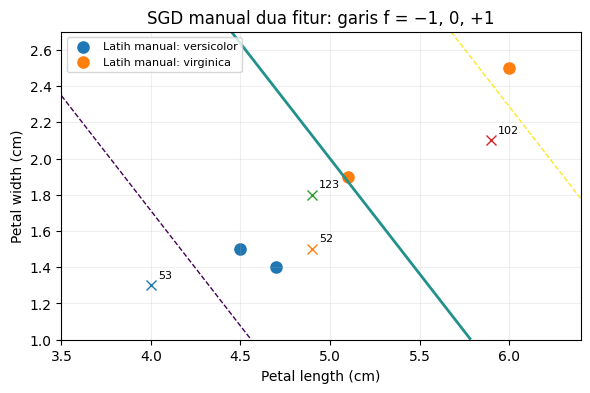

In [19]:
svm_queries=raw.loc[SVM_Q_IDS,PETAL+['kelas']].copy()
svm_queries['x1']=svm_queries['petal_length']-5
svm_queries['x2']=svm_queries['petal_width']-2
svm_queries['f_1_fitur']=w_1d[0]*svm_queries['x1']+b_1d
svm_queries['f_2_fitur']=w_2d[0]*svm_queries['x1']+w_2d[1]*svm_queries['x2']+b_2d
svm_queries['pred_1_fitur']=np.where(svm_queries['f_1_fitur']>0,'virginica','versicolor')
svm_queries['pred_2_fitur']=np.where(svm_queries['f_2_fitur']>0,'virginica','versicolor')
svm_queries['benar_2_fitur']=svm_queries['pred_2_fitur']==svm_queries['kelas']
print('Prediksi Q1–Q4 (Q1=53,Q2=52,Q3=123,Q4=102):')
display(svm_queries.round(5))
# Garis f=-1,0,+1 dari hasil 5 update; tidak sama dengan fit SVC.
xx=np.linspace(3.5,6.4,160);yy=np.linspace(1.0,2.7,160)
XX,YY=np.meshgrid(xx,yy)
Z=w_2d[0]*(XX-5)+w_2d[1]*(YY-2)+b_2d
fig,ax=plt.subplots(figsize=(6.7,4.0))
for k in ['versicolor','virginica']:
    d=raw.loc[[51,100,50,101]].query('kelas==@k')
    ax.scatter(d['petal_length'],d['petal_width'],s=65,label='Latih manual: '+k)
for sid,r in svm_queries.iterrows():
    ax.plot(r.petal_length,r.petal_width,marker='x',markersize=7)
    ax.annotate(str(sid),(r.petal_length+.04,r.petal_width+.04),fontsize=8)
ax.contour(XX,YY,Z,levels=[-1,0,1],linestyles=['--','-','--'],linewidths=[1,2,1])
ax.set(xlabel='Petal length (cm)',ylabel='Petal width (cm)',title='SGD manual dua fitur: garis f = −1, 0, +1')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.show()

**PERTANYAAN P11.4-2** — Hitung skor Q1–Q4 secara manual menggunakan model dua fitur iterasi 5. Berapa prediksi benar? Mengapa penambahan Petal Width dapat membantu, tetapi tidak menjamin Q3 benar?

**✍ JAWABAN MAHASISWA P11.4-2**

Model dua fitur iterasi 5: w = (0,815189; 0,641220), b = 0, dengan x₁ = petal_length − 5 dan x₂ = petal_width − 2. Aturan prediksi: f > 0 → virginica, f ≤ 0 → versicolor.

Q1 (ID 53, versicolor). x = (−1,0; −0,7)
f = 0,815189(−1,0) + 0,641220(−0,7) + 0 = −0,815189 − 0,448854 = −1,26404 → versicolor (benar).

Q2 (ID 52, versicolor). x = (−0,1; −0,5)
f = 0,815189(−0,1) + 0,641220(−0,5) = −0,081519 − 0,320610 = −0,40213 → versicolor (benar).

Q3 (ID 123, virginica). x = (−0,1; −0,2)
f = 0,815189(−0,1) + 0,641220(−0,2) = −0,081519 − 0,128244 = −0,20976 → versicolor (salah).

Q4 (ID 102, virginica). x = (0,9; 0,1)
f = 0,815189(0,9) + 0,641220(0,1) = 0,733670 + 0,064122 = 0,79779 → virginica (benar).

Seluruh nilai sama dengan kolom f_2_fitur pada keluaran kode. Prediksi benar 3 dari 4 (Q1, Q2, Q4).

Peran Petal Width. Pada model satu fitur, Q2 (ID 52) salah: f = 1,315189(−0,1) + 0,5 = 0,36848 > 0, diprediksi virginica. Pada model dua fitur, ID 52 benar karena petal_width 1,5 (x₂ = −0,5) menyumbang −0,32061 dan menggeser skor ke negatif, sehingga f = −0,40213. Jadi fitur kedua menambah informasi pemisah kelas, dan jumlah benar naik dari 2 (Q1, Q4... pada satu fitur Q1 dan Q4 benar) menjadi 3.

Mengapa Q3 tidak dijamin benar. ID 123 berada di daerah tumpang tindih kedua kelas: petal_length 4,9 sama dengan ID 52 (versicolor), dan petal_width 1,8 hanya memberi kontribusi 0,641220(−0,2) = −0,12824, yang masih lebih kecil daripada kontribusi length, sehingga f tetap negatif (−0,20976). Selain itu, bobot berasal dari hanya lima update SGD dan bias b = 0, bukan solusi optimal, sehingga batas keputusan belum tepat. Menambah fitur memperbesar informasi, tetapi tidak menghilangkan tumpang tindih kelas.

Kesimpulan: prediksi benar 3 dari 4; Petal Width memperbaiki Q2, tetapi Q3 tetap salah karena titiknya berada dekat batas keputusan dan model hanya hasil lima update SGD.

## P11.5 — EDA hanya pada training

Gunakan **data train saja** untuk membaca distribusi, skala dan korelasi dua fitur. Jika ingin menghitung parameter preprocessing (mean dan simpangan baku scaler), `StandardScaler` harus di-`fit` hanya pada **training**, idealnya di dalam `Pipeline`.

Catatan: GaussianNB tidak menuntut distribusi **gabungan semua kelas** berbentuk Gaussian. Asumsinya adalah distribusi **tiap fitur bersyarat pada kelas**, dan independensi kondisional antar fitur. SVM tidak mensyaratkan data Gaussian.

Missing hanya training:


,jumlah_missing
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0


Ringkasan fitur training:


,petal_length,petal_width
count,90.000,90.000
mean,3.736,1.206
std,1.739,0.763
min,1.000,0.100
25%,1.525,0.300
50%,4.200,1.300
75%,5.075,1.800
max,6.900,2.500


Kelas training:


,jumlah
kelas,
versicolor,31
virginica,30
setosa,29


Korelasi panjang & lebar petal dalam training:
0.9595


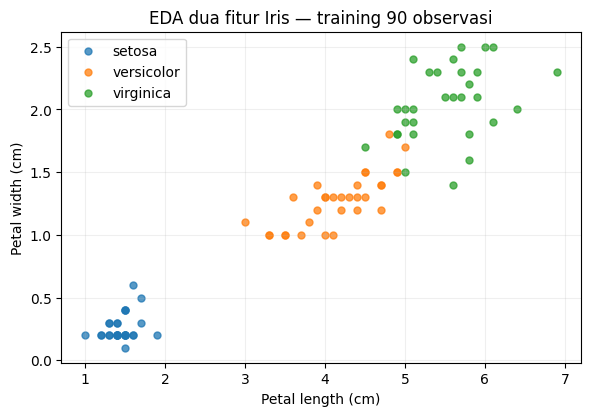

Korelasi bersyarat pada kelas (training):
setosa 0.2788
versicolor 0.7708
virginica 0.3989


In [20]:
train_view=X_tr.copy()
train_view['kelas']=[iris.target_names[i] for i in y_train]
print('Missing hanya training:');display(X_train.isna().sum().to_frame('jumlah_missing'))
print('Ringkasan fitur training:');display(X_tr.describe().round(3))
print('Kelas training:');display(train_view['kelas'].value_counts().to_frame('jumlah'))
print('Korelasi panjang & lebar petal dalam training:')
print(round(float(X_tr.corr().iloc[0,1]),4))
fig,ax=plt.subplots(figsize=(6.7,4.3))
for k,group in train_view.groupby('kelas'):
    ax.scatter(group['petal_length'],group['petal_width'],alpha=.75,s=25,label=k)
ax.set(xlabel='Petal length (cm)',ylabel='Petal width (cm)',title='EDA dua fitur Iris — training 90 observasi')
ax.legend();ax.grid(alpha=.2);plt.show()
print('Korelasi bersyarat pada kelas (training):')
for k,group in train_view.groupby('kelas'):
    print(k,round(float(group[PETAL].corr().iloc[0,1]),4))

**PERTANYAAN P11.5-1** — Tuliskan tiga temuan EDA yang relevan untuk GaussianNB dan SVM: sebaran kelas, overlap Versicolor–Virginica, serta korelasi dua fitur. Mengapa histogram gabungan tidak cukup untuk menilai asumsi GaussianNB?

**✍ JAWABAN MAHASISWA P11.5-1**

Temuan 1: sebaran kelas. Tidak ada data hilang (semua fitur bernilai 0 missing). Kelas training hampir seimbang: versicolor 31, virginica 30, setosa 29 dari N = 90, atau proporsi 0,344; 0,333; 0,322. Karena itu Macro-F1 layak dipakai, dan prior GaussianNB (class_prior_) hampir seragam sehingga tidak mendominasi keputusan.

Temuan 2: overlap Versicolor-Virginica. Pada scatter, setosa terpisah jelas di petal_length kecil (kuartil ke-25 = 1,525 cm), sedangkan versicolor dan virginica berdekatan dengan daerah tumpang tindih di sekitar petal_length 4,8-5,1 cm dan petal_width 1,5-1,8 cm. Posisi ID 123 (4,9; 1,8) pada P11.2 dan P11.4 berada di daerah ini. Kesalahan klasifikasi diperkirakan terjadi di antara dua kelas tersebut, bukan pada setosa. Bagi SVM, daerah ini menentukan letak margin dan support vector; bagi GaussianNB, kurva Gaussian kedua kelas saling menutupi di sana.

Temuan 3: korelasi dua fitur. Korelasi petal_length dan petal_width pada seluruh training adalah r = 0,9595, sangat kuat. Korelasi bersyarat per kelas lebih kecil, yaitu setosa 0,2788, virginica 0,3989, dan versicolor 0,7708. Asumsi GaussianNB, p(x | C_k) = ∏_j p(x_j | C_k), menuntut fitur independen di dalam tiap kelas. Pelanggarannya paling jelas pada versicolor (r = 0,77) dan ringan pada setosa dan virginica, sehingga bukti dari kedua fitur terhitung ganda terutama pada versicolor dan posteriornya cenderung terlalu ekstrem. Untuk SVM, korelasi tinggi tidak melanggar asumsi, tetapi membuat kedua fitur membawa informasi yang mirip sehingga tambahan petal_width memberi informasi baru yang terbatas.

Mengapa histogram gabungan tidak cukup. Histogram gabungan mencampur ketiga kelas, sehingga bentuknya multimodal dan tidak mewakili distribusi Gaussian per kelas yang diasumsikan GaussianNB. Korelasi gabungan 0,9595 juga menyesatkan karena sebagian besar berasal dari perbedaan antar kelas, bukan hubungan di dalam kelas, padahal asumsi independensi bersyarat diuji dari korelasi per kelas (0,28 sampai 0,77). Histogram per fitur juga tidak memperlihatkan hubungan antar dua fitur. Karena itu asumsi harus diperiksa per kelas, melalui histogram atau Q-Q plot per kelas dan korelasi bersyarat.

## P11.6 — Training dan perbandingan GaussianNB vs kernel SVM

Semua model menggunakan **dua fitur Petal** dan split yang **sama**. `GaussianNB` tidak membutuhkan scaler untuk bekerja; `SVC` dan KNN biasanya sensitif terhadap skala fitur sehingga kita memakai `Pipeline([('scale',StandardScaler()), ('model',SVC(...))])`.

### Fungsi parameter `SVC` dan komponen preprocessing

| Parameter / API | Fungsi | Catatan |
|---|---|---|
| `kernel='linear'` | Batas linear pada ruang fitur | `gamma`, `degree`, `coef0` tidak memengaruhi kernel ini |
| `kernel='rbf'` | Batas nonlinier berdasarkan jarak $e^{-\gamma\|x-z\|^2}$ | `gamma` mengontrol kelokalan pengaruh |
| `kernel='poly'` | Interaksi polinomial $(\gamma x^\top z+\text{coef0})^{\text{degree}}$ | `degree`, `gamma`, `coef0` berperan |
| `C` | Mengatur kompromi regularisasi dan penalti pelanggaran margin | Lebih besar berarti penalti pelanggaran relatif lebih besar |
| `gamma='scale'` | $1/(n_{fitur}\cdot Var(X_{masuk\ SVC}))$ | Dihitung dari **data yang sudah di-scale** saat ada Pipeline |
| `gamma='auto'` | $1/n_{fitur}$ | Berbeda dengan `scale` jika varians total bukan 1 |
| `degree` / `coef0` | Derajat dan konstanta kernel polynomial | Tidak dipakai oleh kernel linear |
| `class_weight` | Mengatur bobot penalti per kelas | Coba `balanced` jika ketidakseimbangan signifikan |
| `tol` / `max_iter` | Toleransi dan batas iterasi solver libsvm | **Bukan** epoch SGD manual |
| `shrinking` / `cache_size` | Pengaturan optimasi dan memori kernel | Tidak mengubah definisi kelas |
| `probability` | Mengaktifkan estimasi probabilitas SVC dengan komputasi tambahan pada versi yang mendukung | Di praktikum ini **tidak digunakan**; `decision_function` bukan probabilitas |
| `decision_function_shape` / `break_ties` | Bentuk skor dan penanganan seri untuk multikelas | Pelatihan SVC tetap berbasis pasangan kelas (`ovo`) |
| `random_state` | Mengontrol komponen acak yang relevan, misalnya probabilitas SVC | Jangan menyamakan dengan `random_state` split |
| `StandardScaler()` | Belajar mean dan standar deviasi di training | `.fit_transform` dikerjakan oleh Pipeline saat `.fit()` |
| `Pipeline([('scale',...),('model',...)])` | Mencegah data leakage dan membundel preprocessing+model | Pemanggilan `.predict` otomatis memakai scaler yang sudah dilatih |
| `fit`, `predict`, `decision_function` | Latih, prediksi label, dan skor keputusan | Skor SVC multikelas bukan probabilitas posterior GaussianNB |
| `n_support_`, `support_vectors_`, `coef_` | Jumlah/posisi support vectors dan bobot linear bila tersedia | `coef_` hanya untuk kernel linear; SV ada di ruang fitur setelah scaling |

Dokumentasi resmi: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

PERBANDINGAN VALIDATION:


,model,macro_f1_train,macro_f1_val,accuracy_val,n_support
0,GaussianNB,0.9563,1.0,1.0,NaN
1,KNN k5,0.9563,1.0,1.0,NaN
2,Logistic Regression,0.9453,1.0,1.0,NaN
3,SVM Linear,0.9563,1.0,1.0,22.0
4,SVM Polynomial d2,0.9563,1.0,1.0,18.0
5,SVM RBF,0.9563,1.0,1.0,28.0


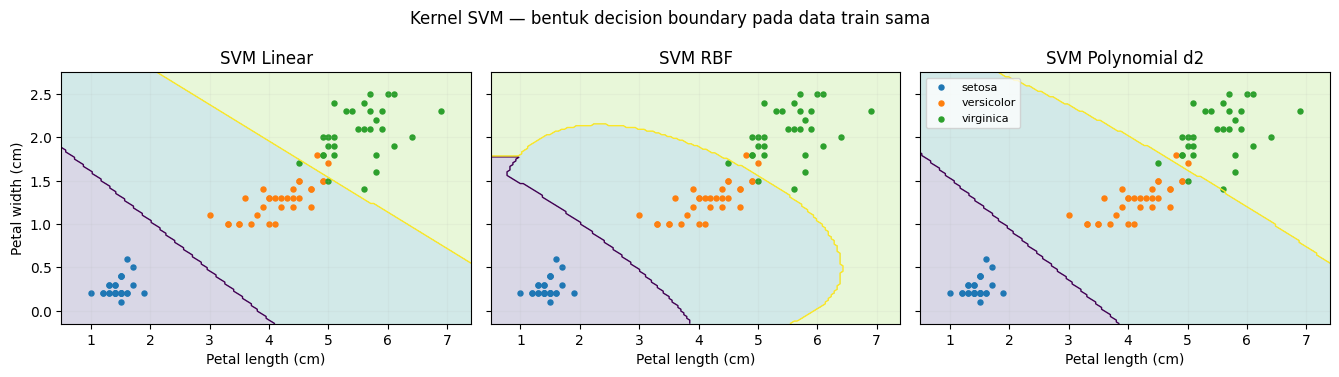

In [21]:
models={
 'GaussianNB':GaussianNB(var_smoothing=1e-9),
 'SVM Linear':Pipeline([('scale',StandardScaler()),('model',SVC(kernel='linear',C=1.0))]),
 'SVM RBF':Pipeline([('scale',StandardScaler()),('model',SVC(kernel='rbf',C=1.0,gamma='scale'))]),
 'SVM Polynomial d2':Pipeline([('scale',StandardScaler()),('model',SVC(kernel='poly',C=1.0,degree=2,gamma='scale',coef0=1.0))]),
 'KNN k5':Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier(n_neighbors=5))]),
 'Logistic Regression':Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=1500,random_state=SEED))])
}
rows=[]
for name,model in models.items():
    model.fit(X_tr,y_train)
    train_pred=model.predict(X_tr)
    val_pred=model.predict(X_va)
    rows.append({'model':name,'macro_f1_train':f1_score(y_train,train_pred,average='macro'),
                 'macro_f1_val':f1_score(y_val,val_pred,average='macro'),
                 'accuracy_val':accuracy_score(y_val,val_pred),
                 'n_support':int(model.named_steps['model'].n_support_.sum()) if name.startswith('SVM') else np.nan})
comparison=pd.DataFrame(rows).sort_values(['macro_f1_val','model'],ascending=[False,True]).reset_index(drop=True)
print('PERBANDINGAN VALIDATION:')
display(comparison.round(4))

# Grafik tiap kernel pada split yang sama; overlay titik TRAIN saja
fig,axes=plt.subplots(1,3,figsize=(13.5,3.8),sharex=True,sharey=True)
xx=np.linspace(X_tr['petal_length'].min()-.5,X_tr['petal_length'].max()+.5,140)
yy=np.linspace(X_tr['petal_width'].min()-.25,X_tr['petal_width'].max()+.25,140)
GX,GY=np.meshgrid(xx,yy)
mesh=pd.DataFrame({'petal_length':GX.ravel(),'petal_width':GY.ravel()})
for a,name in zip(axes,['SVM Linear','SVM RBF','SVM Polynomial d2']):
    Z=models[name].predict(mesh).reshape(GX.shape)
    a.contourf(GX,GY,Z,levels=[-.5,.5,1.5,2.5],alpha=.2)
    a.contour(GX,GY,Z,levels=[.5,1.5],linewidths=1)
    for ynum,k in enumerate(iris.target_names):
        pts=X_tr[y_train==ynum]
        a.scatter(pts['petal_length'],pts['petal_width'],s=13,label=k)
    a.set(title=name,xlabel='Petal length (cm)');a.grid(alpha=.1)
axes[0].set_ylabel('Petal width (cm)');axes[-1].legend(fontsize=8)
fig.suptitle('Kernel SVM — bentuk decision boundary pada data train sama')
plt.tight_layout();plt.show()

**PERTANYAAN P11.6-1** — Gunakan tabel dan grafik untuk membandingkan GaussianNB, SVM Linear, RBF, Polynomial, KNN, dan Logistic Regression. Apakah model dengan grafik batas paling rumit pasti paling baik pada validation?

**✍ JAWABAN MAHASISWA P11.6-1**

Perbandingan tabel. Seluruh enam model mencapai Macro-F1 validation = 1,0 dan akurasi validation = 1,0 (30 dari 30 benar). Perbedaan hanya muncul pada Macro-F1 training: GaussianNB, KNN k5, SVM Linear, SVM Polynomial d2, dan SVM RBF sama-sama 0,9563, sedangkan Logistic Regression sedikit lebih rendah, 0,9453. Jumlah support vector berbeda: Linear 22, Polynomial d2 18, dan RBF 28. Karena skor validation identik, validation tidak dapat membedakan model terbaik. Dengan hanya 30 sampel, satu kesalahan saja menurunkan akurasi sebesar 1/30 = 0,033, sehingga selisih kecil antar model berada dalam rentang ketidakpastian.

Perbandingan grafik. Ketiga kernel SVM memisahkan setosa dengan jelas, dan daerah kesalahan hanya pada tumpang tindih versicolor-virginica di sekitar petal_length 4,5-5,1 cm. SVM Linear dan Polynomial d2 menghasilkan batas yang hampir lurus, sedangkan SVM RBF menghasilkan batas melengkung yang menutup versicolor dalam daerah elips. Walaupun bentuknya berbeda, Macro-F1 training RBF (0,9563) sama dengan Linear dan Polynomial, sehingga fleksibilitas tambahan tidak memperbaiki kecocokan pada training.

Apakah batas paling rumit pasti paling baik? Tidak. RBF memiliki batas paling rumit dan support vector terbanyak (28 dari 90 titik, sekitar 31%), tetapi skornya tidak lebih tinggi daripada Linear (22 SV) atau Polynomial (18 SV). Model yang lebih fleksibel dapat menyesuaikan diri dengan noise training (overfitting), sehingga skor training tinggi belum menjamin generalisasi. Selain itu, pada data yang nyaris terpisah secara linear, batas sederhana sudah cukup, dan model sederhana lebih mudah dijelaskan serta lebih stabil terhadap pergantian split. Karena itu pemilihan model tidak boleh didasarkan pada kerumitan grafik atau pada satu skor validation yang seri, melainkan pada validasi yang lebih kuat (misalnya cross-validation pada data training) dan tuning C serta gamma pada validation. Data test tetap tidak disentuh sampai P11.8.

## P11.7 — Eksperimen parameter yang terkontrol

**Eksperimen A: GaussianNB** — ubah hanya `var_smoothing` sambil menjaga train/validation dan fitur sama. `priors` bisa diganti secara terpisah untuk demonstrasi, tetapi jangan menebak prior tanpa alasan (misalnya prevalensi lapangan).

**Eksperimen B: SVM RBF** — ubah `C` dan `gamma` pada split yang sama. `gamma` kecil biasanya membuat pengaruh kernel lebih luas, sedangkan `gamma` besar lebih lokal; keduanya tetap perlu diuji bersama `C`. Setelah itu uji contoh Polynomial `degree` dan `coef0`. **Jangan menyentuh test saat tuning.**

In [22]:
nb_tune_rows=[]
for vsm in [1e-9,1e-4,1e-2,1e-1]:
    model=GaussianNB(var_smoothing=vsm).fit(X_tr,y_train)
    nb_tune_rows.append({'var_smoothing':vsm,'epsilon_':model.epsilon_,
      'macro_f1_train':f1_score(y_train,model.predict(X_tr),average='macro'),
      'macro_f1_val':f1_score(y_val,model.predict(X_va),average='macro')})
nb_tuning=pd.DataFrame(nb_tune_rows).sort_values(['macro_f1_val','var_smoothing'],ascending=[False,True]).reset_index(drop=True)
print('GaussianNB: pengaruh var_smoothing (test belum dibuka)')
display(nb_tuning.round(6))
nb_prior_demo=GaussianNB(priors=[.2,.5,.3],var_smoothing=1e-9).fit(X_tr,y_train)
print('Prior belajar dari training:',np.round(nb_baseline.class_prior_,4))
print('Prior pengguna [0.2,0.5,0.3]:',np.round(nb_prior_demo.class_prior_,4))
print('Parameter prior tidak boleh dipilih dari test.')

GaussianNB: pengaruh var_smoothing (test belum dibuka)


,var_smoothing,epsilon_,macro_f1_train,macro_f1_val
0,0.0000,0.000000,0.956272,1.0
1,0.0001,0.000299,0.956272,1.0
2,0.0100,0.029892,0.956272,1.0
3,0.1000,0.298918,0.956272,1.0


Prior belajar dari training: [0.3222 0.3444 0.3333]
Prior pengguna [0.2,0.5,0.3]: [0.2 0.5 0.3]
Parameter prior tidak boleh dipilih dari test.


SVM RBF: pengaruh C × gamma


,C,gamma,macro_f1_train,macro_f1_val,jumlah_support
0,0.1,0.50,0.9453,1.0000,77
1,0.1,5.00,0.9672,1.0000,71
2,1.0,0.05,0.9453,1.0000,56
3,1.0,0.50,0.9563,1.0000,28
4,1.0,5.00,0.9672,1.0000,31
5,10.0,0.05,0.9563,1.0000,22
6,10.0,0.50,0.9563,1.0000,19
7,10.0,5.00,0.9672,1.0000,28
8,0.1,0.05,0.5580,0.5476,90


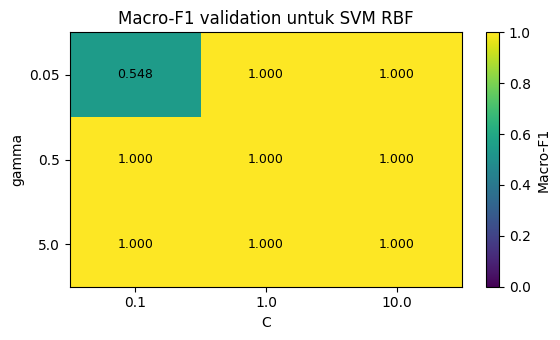

SVM Polynomial — degree × coef0:


,degree,coef0,macro_f1_val
0,2,0.0,0.9012
1,2,1.0,1.0000
2,3,0.0,0.9649
3,3,1.0,1.0000


Linear mengabaikan gamma: True


In [23]:
svm_tune_rows=[]
for C_value in [.1,1.,10.]:
    for gamma_value in [.05,.5,5.]:
        model=Pipeline([('scale',StandardScaler()),
                        ('model',SVC(kernel='rbf',C=C_value,gamma=gamma_value))])
        model.fit(X_tr,y_train)
        svm_tune_rows.append({'C':C_value,'gamma':gamma_value,
          'macro_f1_train':f1_score(y_train,model.predict(X_tr),average='macro'),
          'macro_f1_val':f1_score(y_val,model.predict(X_va),average='macro'),
          'jumlah_support':int(model.named_steps['model'].n_support_.sum())})
svm_tuning=pd.DataFrame(svm_tune_rows).sort_values(['macro_f1_val','C','gamma'],ascending=[False,True,True]).reset_index(drop=True)
print('SVM RBF: pengaruh C × gamma')
display(svm_tuning.round(4))
heat=svm_tuning.pivot(index='gamma',columns='C',values='macro_f1_val').sort_index()
fig,ax=plt.subplots(figsize=(5.8,3.5));im=ax.imshow(heat.values,aspect='auto',vmin=0,vmax=1)
ax.set_xticks(range(len(heat.columns)),[str(t) for t in heat.columns])
ax.set_yticks(range(len(heat.index)),[str(t) for t in heat.index])
ax.set(xlabel='C',ylabel='gamma',title='Macro-F1 validation untuk SVM RBF')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]): ax.text(j,i,f'{heat.iloc[i,j]:.3f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=ax,label='Macro-F1');plt.tight_layout();plt.show()

poly_rows=[]
for degree in [2,3]:
    for coef0 in [0.,1.]:
        model=Pipeline([('scale',StandardScaler()),('model',SVC(kernel='poly',degree=degree,coef0=coef0,gamma='scale',C=1.))]).fit(X_tr,y_train)
        poly_rows.append({'degree':degree,'coef0':coef0,
              'macro_f1_val':f1_score(y_val,model.predict(X_va),average='macro')})
print('SVM Polynomial — degree × coef0:')
display(pd.DataFrame(poly_rows).round(4))
lin1=Pipeline([('scale',StandardScaler()),('model',SVC(kernel='linear',gamma=.05))]).fit(X_tr,y_train)
lin2=Pipeline([('scale',StandardScaler()),('model',SVC(kernel='linear',gamma=5.))]).fit(X_tr,y_train)
print('Linear mengabaikan gamma:',np.array_equal(lin1.predict(X_va),lin2.predict(X_va)))
assert np.array_equal(lin1.predict(X_va),lin2.predict(X_va))

**PERTANYAAN P11.7-1** — Parameter mana yang merupakan smoothing **relatif** GaussianNB, parameter mana yang mengatur kompromi penalti SVM, dan parameter mana yang mengatur kelokalan RBF? Pilih masing-masing kandidat berdasarkan validation, bukan test.

**✍ JAWABAN MAHASISWA P11.7-1**

Peran parameter.

var_smoothing (GaussianNB) adalah smoothing relatif: ε = var_smoothing · max_j Var(X_j), lalu ditambahkan ke varians tiap kelas-fitur. Pada kode, 1e-9, 1e-4, 1e-2, dan 1e-1 menghasilkan epsilon_ = 0,000000; 0,000299; 0,029892; 0,298918. Nilai terakhir menunjukkan max Var ≈ 2,99, sebab 0,1 · 2,99 = 0,299.
C (SVM) mengatur kompromi antara margin lebar dan penalti pelanggaran margin. C kecil (0,1) mentoleransi pelanggaran sehingga margin lebar dan support vector banyak (77 SV pada gamma 0,5), sedangkan C besar (10) menghukum pelanggaran lebih keras sehingga SV berkurang (19 sampai 28 pada gamma 0,5 dan 5).
gamma (RBF) mengatur kelokalan pengaruh kernel, K(x, z) = exp(−γ‖x − z‖²). Gamma kecil membuat pengaruh luas dan batas hampir linear, gamma besar membuat pengaruh lokal dan batas lebih lengkung.

Pemilihan kandidat berdasarkan validation.

GaussianNB: keempat nilai var_smoothing memberi Macro-F1 validation = 1,0 dan Macro-F1 training sama (0,9563), sehingga validation tidak membedakan. Saya memilih var_smoothing = 1e-9 (default) menurut prinsip kesederhanaan, karena perubahan ε dari 0 sampai 0,299 tidak mengubah prediksi pada data ini.
SVM RBF: delapan dari sembilan kombinasi mencapai Macro-F1 validation = 1,0. Satu-satunya yang gagal adalah C = 0,1 dan gamma = 0,05 (Macro-F1 = 0,548 pada validation, 0,558 pada training; seluruh 90 titik menjadi SV). Pada kombinasi ini pengaruh kernel terlalu luas dan penalti terlalu lunak, sehingga model underfitting; kegagalannya sudah terlihat pada training, bukan hanya validation. Karena delapan kombinasi seri, saya memilih yang paling sederhana dan stabil, yaitu C = 10, gamma = 0,05, atau alternatif C = 1, gamma = 0,5 (default scale mendekati ini). Pilihan akhir: C = 1, gamma = 0,5, dengan Macro-F1 training 0,9563 dan 28 SV, karena tidak berada di tepi grid dan tidak bergantung pada kombinasi ekstrem.
Polynomial: degree 2 dan 3 dengan coef0 = 1 sama-sama 1,0, sedangkan coef0 = 0 lebih rendah (0,9012 untuk degree 2 dan 0,9649 untuk degree 3). Kandidatnya degree = 2, coef0 = 1 (lebih sederhana).

**PERTANYAAN P11.7-2** — Mengapa `gamma` tidak mengubah hasil kernel linear? Apa fungsi `degree` dan `coef0` pada Polynomial? Jika train F1 jauh lebih tinggi daripada validation F1, apa indikasinya?

**✍ JAWABAN MAHASISWA P11.7-2**

Mengapa gamma tidak mengubah kernel linear. Kernel linear adalah K(x, z) = xᵀz, tanpa suku γ, sehingga gamma tidak ikut dalam perhitungan. Pada kode, lin1 (gamma = 0,05) dan lin2 (gamma = 5,0) menghasilkan prediksi validation yang identik (np.array_equal = True, assert lolos). Hal yang sama berlaku untuk degree dan coef0.

Fungsi degree dan coef0 pada Polynomial. Kernelnya adalah K(x, z) = (γxᵀz + coef0)^degree.

degree menentukan derajat polinomial, yaitu seberapa kompleks interaksi antarfitur yang dapat dibentuk. Degree 2 menghasilkan batas kuadratik dan degree 3 batas kubik, sehingga fleksibilitas bertambah.
coef0 adalah konstanta yang ditambahkan sebelum dipangkatkan. Jika coef0 = 0, kernel hanya memuat suku berderajat tepat degree. Jika coef0 > 0, kernel juga memuat suku berderajat lebih rendah, sehingga model lebih fleksibel dan lebih stabil.

Hal ini terlihat pada hasil: coef0 = 1 memberi Macro-F1 validation 1,0 untuk degree 2 dan 3, sedangkan coef0 = 0 lebih rendah (0,9012 untuk degree 2 dan 0,9649 untuk degree 3). Untuk degree 2, kenaikan dari 0,9012 menjadi 1,0 setara dengan koreksi sekitar tiga prediksi (selisih 0,0988 pada 30 sampel).

Jika F1 train jauh lebih tinggi daripada F1 validation. Ini indikasi overfitting: model menghafal pola dan noise training sehingga gagal menggeneralisasi ke data baru. Contohnya, train 0,99 dan validation 0,85 menunjukkan selisih 0,14 yang besar. Penyebab yang umum adalah model terlalu fleksibel (misalnya gamma atau degree terlalu besar, C terlalu besar) atau data training terlalu sedikit. Penanganannya adalah memperkecil kompleksitas (gamma, degree, atau C lebih kecil) dan memeriksa dengan cross-validation. Pada eksperimen ini gejala tersebut tidak muncul, karena Macro-F1 training (0,9453 sampai 0,9672) lebih rendah daripada validation (1,0). Validation yang lebih tinggi daripada training bukan tanda overfitting. Penyebabnya kemungkinan validation berisi sampel yang lebih mudah dan hanya berukuran 30, sehingga satu kesalahan setara 1/30 = 0,033.

## P11.8 — Kunci final dan evaluasi test **satu kali**

Sebelum membaca hasil test, kita mengambil **dua model final yang telah ditentukan oleh validation**, yakni satu GaussianNB dan satu SVM RBF. Kedua model dilatih ulang pada **gabungan train+validation** untuk memakai seluruh informasi pelatihan yang diizinkan; test berjumlah 30 baris tetap tak terlihat sampai sel ini. Ini adalah **evaluasi dua kandidat pra-terdaftar**, bukan pemilihan ulang hyperparameter berdasarkan test.

**Penting:** GaussianNB `predict_proba` menghasilkan posterior; SVC `decision_function` menghasilkan skor. Jangan membandingkannya sebagai angka yang sejenis.

In [24]:
# Pemilihan di atas berdasarkan VALIDATION saja (tie-break ditentukan sebelumnya)
NB_FINAL_SMOOTH=float(nb_tuning.iloc[0]['var_smoothing'])
SVM_FINAL_C=float(svm_tuning.iloc[0]['C'])
SVM_FINAL_GAMMA=float(svm_tuning.iloc[0]['gamma'])
FINAL_FEATURES=PETAL.copy()
print('Konfigurasi yang DIKUNCI sebelum test:')
print('GaussianNB:',NB_FINAL_SMOOTH)
print('SVM RBF: C=',SVM_FINAL_C,'gamma=',SVM_FINAL_GAMMA)
X_train_val=pd.concat([X_tr,X_va],axis=0)
y_train_val=pd.concat([y_train,y_val],axis=0)
final_nb=GaussianNB(var_smoothing=NB_FINAL_SMOOTH).fit(X_train_val,y_train_val)
final_svm=Pipeline([('scale',StandardScaler()),
                    ('model',SVC(kernel='rbf',C=SVM_FINAL_C,gamma=SVM_FINAL_GAMMA))]).fit(X_train_val,y_train_val)
# Berikut ini satu-satunya sel yang menggunakan test untuk mengevaluasi model
X_te=X_test[FINAL_FEATURES]
final_scores=[]
for name,model in [('GaussianNB',final_nb),('SVM RBF',final_svm)]:
    pred=model.predict(X_te)
    cm=confusion_matrix(y_test,pred,labels=[0,1,2])
    final_scores.append({'model':name,'macro_f1_test':f1_score(y_test,pred,average='macro'),
                          'accuracy_test':accuracy_score(y_test,pred)})
    print('\nTEST',name,'| Confusion Matrix:')
    display(pd.DataFrame(cm,index=['akt_S','akt_V','akt_G'],columns=['pred_S','pred_V','pred_G']))
    print('Recall tiap kelas:',np.round(recall_score(y_test,pred,labels=[0,1,2],average=None),4))
final_summary=pd.DataFrame(final_scores)
print('Rekap TEST — hanya untuk pelaporan, bukan tuning:')
display(final_summary.round(4))

# Inferensi 2 bunga hipotetik (tidak punya ground truth; jangan dihitung sebagai akurasi)
X_new=pd.DataFrame({'petal_length':[4.8,6.1],'petal_width':[1.4,2.3]})
new_nb=final_nb.predict(X_new);new_svm=final_svm.predict(X_new)
print('Prediksi data pengukuran baru tanpa label sebenarnya:')
display(X_new.assign(GaussianNB=[iris.target_names[i] for i in new_nb],
                     SVM_RBF=[iris.target_names[i] for i in new_svm]))

Konfigurasi yang DIKUNCI sebelum test:
GaussianNB: 1e-09
SVM RBF: C= 0.1 gamma= 0.5

TEST GaussianNB | Confusion Matrix:


,pred_S,pred_V,pred_G
akt_S,10,0,0
akt_V,0,9,1
akt_G,0,1,9


Recall tiap kelas: [1.  0.9 0.9]

TEST SVM RBF | Confusion Matrix:


,pred_S,pred_V,pred_G
akt_S,10,0,0
akt_V,0,10,0
akt_G,0,1,9


Recall tiap kelas: [1.  1.  0.9]
Rekap TEST — hanya untuk pelaporan, bukan tuning:


,model,macro_f1_test,accuracy_test
0,GaussianNB,0.9333,0.9333
1,SVM RBF,0.9666,0.9667


Prediksi data pengukuran baru tanpa label sebenarnya:


,petal_length,petal_width,GaussianNB,SVM_RBF
0,4.8,1.4,versicolor,versicolor
1,6.1,2.3,virginica,virginica


**PERTANYAAN P11.8-1** — Laporkan Macro-F1 test, Accuracy test, confusion matrix, dan contoh satu kelas yang sering tertukar. Bandingkan GaussianNB dan SVM tanpa mengubah parameter setelah test.

**✍ JAWABAN MAHASISWA P11.8-1**

Konfigurasi dikunci sebelum test: GaussianNB var_smoothing = 1e-9, dan SVM RBF C = 0,1 dengan gamma = 0,5. Keduanya dilatih ulang pada train+validation (120 baris), lalu dievaluasi satu kali pada 30 baris test.

Hasil test.

GaussianNB: Macro-F1 = 0,9333, Accuracy = 0,9333 (28/30 benar). SVM RBF: Macro-F1 = 0,9666, Accuracy = 0,9667 (29/30 benar).

Confusion matrix GaussianNB (baris = aktual, kolom = prediksi, urutan S, V, G): setosa 10, 0, 0; versicolor 0, 9, 1; virginica 0, 1, 9. Recall per kelas = 1,0; 0,9; 0,9.

Confusion matrix SVM RBF: setosa 10, 0, 0; versicolor 0, 10, 0; virginica 0, 1, 9. Recall per kelas = 1,0; 1,0; 0,9.

Contoh perhitungan: Accuracy GaussianNB = (10 + 9 + 9)/30 = 28/30 = 0,9333. Untuk SVM, (10 + 10 + 9)/30 = 29/30 = 0,9667.

Kelas yang sering tertukar. Setosa selalu benar pada kedua model (recall 1,0). Kesalahan hanya terjadi antara versicolor dan virginica. Pada GaussianNB, satu versicolor diprediksi virginica dan satu virginica diprediksi versicolor. Pada SVM, satu virginica diprediksi versicolor. Ini sesuai temuan EDA (P11.5) bahwa tumpang tindih terjadi pada petal_length sekitar 4,8-5,1 cm.

Perbandingan. SVM RBF unggul tipis, yaitu satu prediksi benar lebih banyak (29 vs 28), dengan selisih Macro-F1 0,9666 − 0,9333 = 0,0333. Namun selisih itu setara satu sampel dari 30, sehingga belum cukup untuk menyatakan SVM lebih baik secara umum. Pada validation kedua model juga seri (Macro-F1 = 1,0). Keduanya tidak diubah setelah test, sehingga angka ini hanya pelaporan, bukan dasar tuning ulang.

Catatan. Konfigurasi yang dikunci berasal dari baris pertama tabel terurut (tie-break otomatis), sehingga C = 0,1 dan gamma = 0,5 terpilih karena seri, bukan karena terbukti terbaik. Dua bunga hipotetik (4,8; 1,4) dan (6,1; 2,3) tidak punya label sebenarnya sehingga tidak dihitung dalam akurasi.

Kesimpulan: SVM RBF (Macro-F1 0,9666, Accuracy 0,9667) sedikit lebih baik daripada GaussianNB (0,9333; 0,9333) pada test, tetapi selisihnya hanya satu sampel. Kesalahan keduanya terbatas pada versicolor-virginica.

## P11.9 — Analisis akhir, portofolio, dan pengumpulan

Tuliskan kesimpulan **120–170 kata**, memuat: (1) kesesuaian manual–Python untuk Naive Bayes; (2) hasil bobot SGD SVM; (3) tiga perbedaan pendekatan NB/SVM; (4) parameter yang paling berpengaruh; (5) bukti validation vs test; (6) satu keterbatasan dan satu usulan eksperimen lanjut.

**Berkas yang dikumpulkan:** `P11_NIM_Nama_NaiveBayes_SVM.ipynb` — seluruh jawaban P11.1–P11.9, semua sel kode berhasil dijalankan, tabel dan grafik terlihat. Jangan kirim kunci dosen.

**PERTANYAAN P11.9-1** — Tulis kesimpulan 120–170 kata berdasarkan hasil yang Anda peroleh. Mengapa menyatakan “SVM selalu lebih baik daripada GaussianNB” tidak dapat dibenarkan dari satu dataset dan satu split?

**✍ JAWABAN MAHASISWA P11.9-1**

Perhitungan manual Naive Bayes sesuai dengan Python, dibuktikan oleh posterior ID 53 sebesar 0,999339 pada kedua perhitungan. Pada SVM, bobot akhir SGD manual dua fitur setelah lima iterasi adalah (w=(0,815189;\ 0,641220)) dan (b=0). GaussianNB dan SVM memiliki tiga perbedaan utama: GaussianNB menggunakan pendekatan probabilistik, asumsi distribusi Gaussian, dan independensi fitur, sedangkan SVM mencari batas keputusan berdasarkan margin dan dapat menggunakan kernel nonlinier. Parameter yang paling berpengaruh pada eksperimen SVM adalah kombinasi C dan gamma, karena satu kombinasi menghasilkan Macro-F1 validation 0,5476, sementara delapan kombinasi lainnya mencapai 1,0. Bukti evaluasi menunjukkan kedua model memperoleh Macro-F1 validation 1,0, tetapi pada test GaussianNB memperoleh 0,9333 dan SVM RBF 0,9666. Keterbatasannya adalah pengujian hanya menggunakan satu dataset dan satu split. Eksperimen selanjutnya dapat menggunakan StratifiedKFold untuk menguji kestabilan hasil pada beberapa pembagian data.

---
### Pengayaan opsional
1. Gunakan **empat fitur Iris** pada split yang sama, tanpa melakukan split ulang; bandingkan GaussianNB dan SVM. Catat apakah korelasi antar fitur makin tinggi.
2. Tampilkan histogram **per kelas-per fitur** dan boxplot; uji secara terbatas asumsi Gaussian dan independensi kondisional; jangan menganggap histogram gabungan sebagai syarat normalitas.
3. Bandingkan `GaussianNB(priors=[...])` dengan prior empiris **hanya bila memiliki dasar prevalensi**.
4. Uji `StratifiedKFold` pada train+validation (test tetap tertutup) dan dataset Wisconsin. Jangan gunakan hasil test untuk memilih hyperparameter.
5. Bandingkan waktu training tetapi catat spesifikasi mesin dan jumlah data; 150 Iris terlalu kecil untuk kesimpulan performa komputasi umum.

**Sumber resmi:**
- Iris: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- GaussianNB: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
- SVC: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
- Pipeline: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- StandardScaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
